# Analyse exploratoire et nettoyage : Breast Cancer Wisconsin

Jeu de données : 569 tumeurs, 30 mesures sur des noyaux cellulaires et un diagnostic (M = maligne, B = bénigne).

Plan :
1. Chargement et structure
2. Qualité des données
3. Répartition des classes
4. Distributions et outliers
5. Corrélations
6. Nettoyage
7. Export

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\pierr\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "c:\Users\pierr\anaconda3\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "c:\Users\pierr\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "c:\Users\pierr\anaconda3\Lib\site-pack

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\pierr\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "c:\Users\pierr\anaconda3\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "c:\Users\pierr\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "c:\Users\pierr\anaconda3\Lib\site-pack

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



## 1. Chargement et structure

In [3]:
df = pd.read_csv("data/bcw_data.csv")
print("Dimensions :", df.shape)
df.head()

Dimensions : (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

Les 30 variables sont 10 mesures (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), chacune en version `_mean`, `_se` (erreur standard) et `_worst` (pire valeur).

## 2. Qualité des données

In [5]:
manquantes = df.isna().sum()
print("Valeurs manquantes (colonnes concernées) :")
print(manquantes[manquantes > 0])
print()
print("Lignes dupliquées :", df.duplicated().sum())
print("id dupliqués      :", df["id"].duplicated().sum())
print("Valeurs de diagnosis :", df["diagnosis"].unique())

Valeurs manquantes (colonnes concernées) :
Unnamed: 32    569
dtype: int64

Lignes dupliquées : 0
id dupliqués      : 0
Valeurs de diagnosis : <ArrowStringArray>
['M', 'B']
Length: 2, dtype: str


`Unnamed: 32` est entièrement vide : c'est un artefact d'export, on la supprimera.

In [6]:
num = df.drop(columns=["id", "diagnosis", "Unnamed: 32"])

print("Valeurs négatives :", (num < 0).sum().sum())

zeros = (num == 0).sum()
print("\nZéros par colonne :")
print(zeros[zeros > 0])

Valeurs négatives : 0

Zéros par colonne :
concavity_mean          13
concave points_mean     13
concavity_se            13
concave points_se       13
concavity_worst         13
concave points_worst    13
dtype: int64


In [7]:
# Les zéros de concavité concernent-ils les mêmes lignes ? Quel diagnostic ?
lignes_zero = df[df["concavity_mean"] == 0]
print("Mêmes lignes pour concave points :", (lignes_zero["concave points_mean"] == 0).all())
print(lignes_zero["diagnosis"].value_counts())

Mêmes lignes pour concave points : True
diagnosis
B    13
Name: count, dtype: int64


Les 13 zéros sont les mêmes lignes, toutes bénignes : ce sont des cellules sans concavité, pas des valeurs manquantes. On les garde.

In [8]:
# Cohérence : la pire valeur ne doit jamais être inférieure à la moyenne
for f in ["radius", "texture", "perimeter", "area", "smoothness",
          "compactness", "concavity", "concave points", "symmetry", "fractal_dimension"]:
    n = (num[f + "_worst"] < num[f + "_mean"]).sum()
    print(f"{f:20s} worst < mean : {n}")

radius               worst < mean : 0
texture              worst < mean : 0
perimeter            worst < mean : 0
area                 worst < mean : 0
smoothness           worst < mean : 0
compactness          worst < mean : 0
concavity            worst < mean : 0
concave points       worst < mean : 0
symmetry             worst < mean : 0
fractal_dimension    worst < mean : 0


## 3. Répartition des classes

diagnosis
B    357
M    212
Name: count, dtype: int64
diagnosis
B    0.627
M    0.373
Name: count, dtype: float64


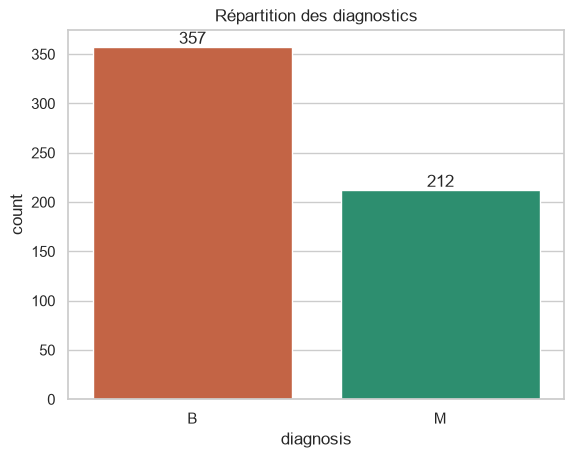

In [9]:
vc = df["diagnosis"].value_counts()
print(vc)
print((vc / len(df)).round(3))

ax = sns.countplot(data=df, x="diagnosis", hue="diagnosis", palette=["#1D9E75", "#D85A30"], order=["B", "M"], legend=False)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Répartition des diagnostics")
plt.show()

357 bénignes (62,7 %) contre 212 malignes (37,3 %) : déséquilibre modéré, acceptable pour un perceptron.

## 4. Distributions et outliers

In [10]:
num.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
texture_mean,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
perimeter_mean,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
area_mean,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
smoothness_mean,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
compactness_mean,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
concavity_mean,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
concave points_mean,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
symmetry_mean,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
fractal_dimension_mean,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


In [11]:
# Asymétrie : les variables les plus déséquilibrées
num.skew().sort_values(ascending=False).head(8).round(2)

area_se                 5.45
concavity_se            5.11
fractal_dimension_se    3.92
perimeter_se            3.44
radius_se               3.09
smoothness_se           2.31
symmetry_se             2.20
compactness_se          1.90
dtype: float64

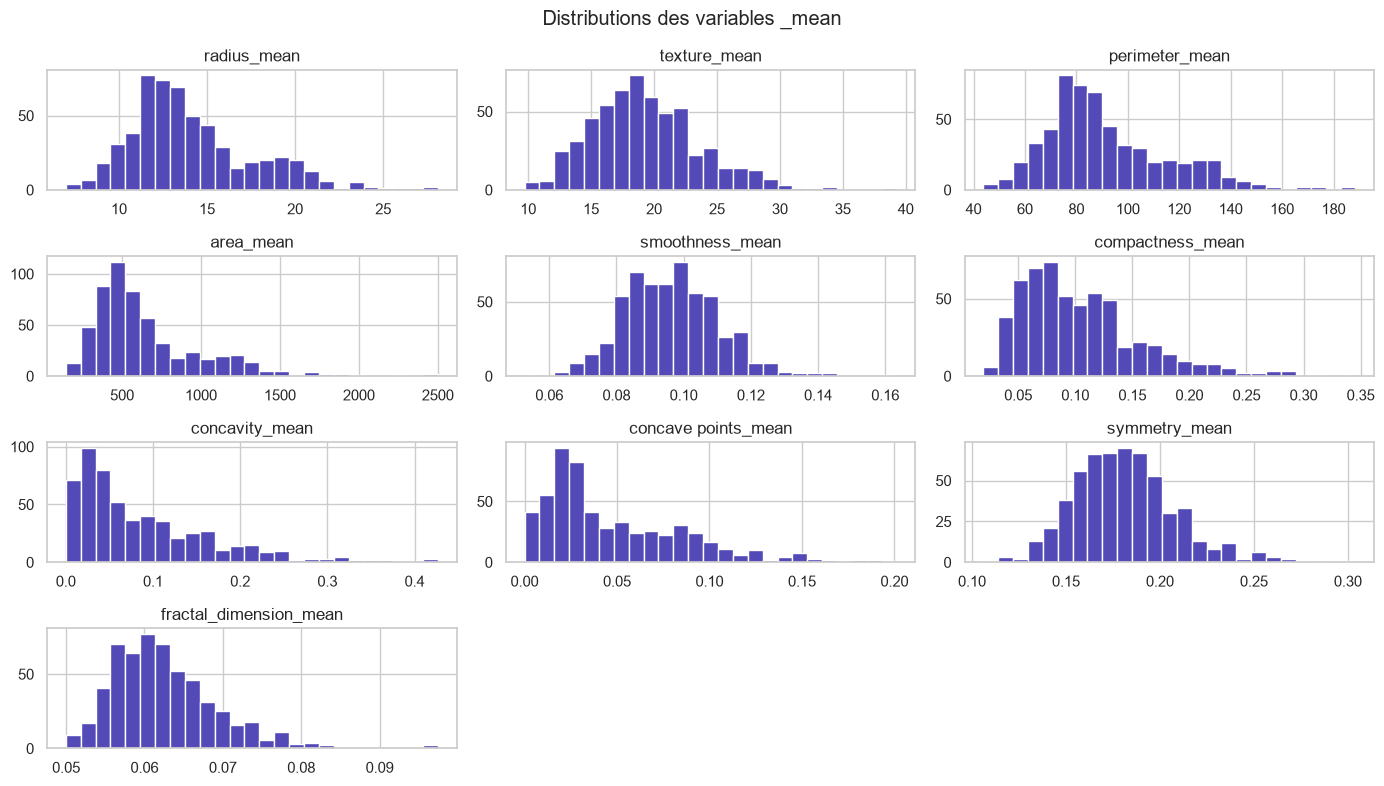

In [12]:
mean_cols = [c for c in num.columns if c.endswith("_mean")]
num[mean_cols].hist(bins=25, figsize=(14, 8), color="#534AB7")
plt.suptitle("Distributions des variables _mean")
plt.tight_layout()
plt.show()

In [13]:
# Outliers selon la règle de l'IQR (1,5 x IQR)
q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
masque = (num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)

print("Outliers par colonne (top 10) :")
print(masque.sum().sort_values(ascending=False).head(10))
print("\nLignes avec au moins un outlier :", masque.any(axis=1).sum(), "sur", len(num))

Outliers par colonne (top 10) :
area_se                    65
radius_se                  38
perimeter_se               38
area_worst                 35
smoothness_se              30
fractal_dimension_se       28
compactness_se             28
symmetry_se                27
area_mean                  25
fractal_dimension_worst    24
dtype: int64

Lignes avec au moins un outlier : 171 sur 569


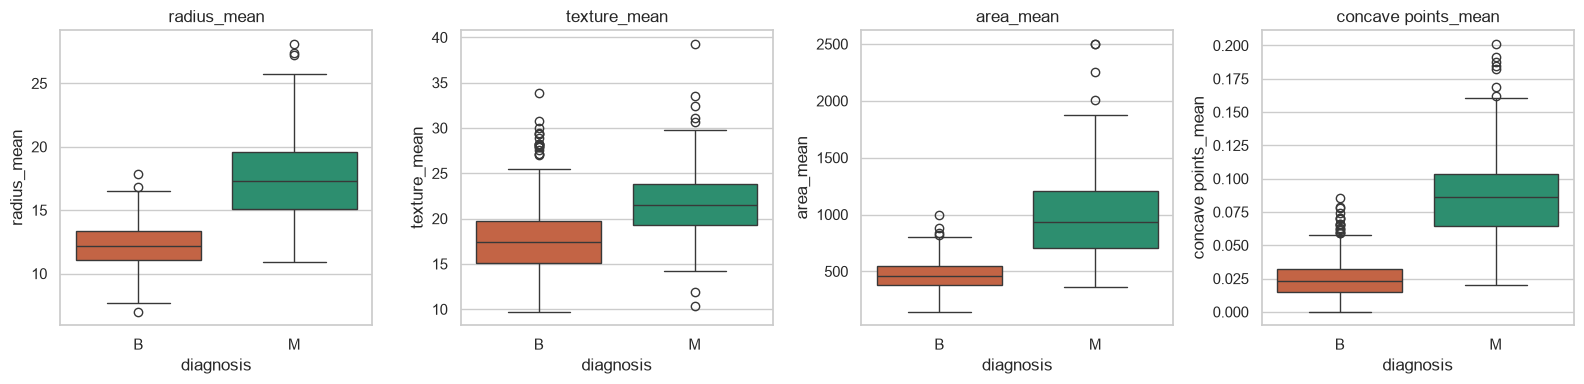

In [14]:
cols = ["radius_mean", "texture_mean", "area_mean", "concave points_mean"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, cols):
    sns.boxplot(data=df, x="diagnosis", y=c, hue="diagnosis", order=["B", "M"],
                palette=["#1D9E75", "#D85A30"], legend=False, ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

Les outliers sont de vraies mesures de tumeurs (souvent des cas malins de grande taille). On les **conserve** : les supprimer ferait perdre de l'information et fausserait l'analyse.

## 5. Corrélations

In [15]:
y = df["diagnosis"].map({"B": 0, "M": 1})
cor_cible = num.corrwith(y).sort_values(key=abs, ascending=False)
print("Top 10 corrélations avec le diagnostic (M = 1) :")
print(cor_cible.head(10).round(3))
print("\nPlus faibles :")
print(cor_cible.tail(5).round(3))

Top 10 corrélations avec le diagnostic (M = 1) :
concave points_worst    0.794
perimeter_worst         0.783
concave points_mean     0.777
radius_worst            0.776
perimeter_mean          0.743
area_worst              0.734
radius_mean             0.730
area_mean               0.709
concavity_mean          0.696
concavity_worst         0.660
dtype: float64

Plus faibles :
fractal_dimension_se      0.078
smoothness_se            -0.067
fractal_dimension_mean   -0.013
texture_se               -0.008
symmetry_se              -0.007
dtype: float64


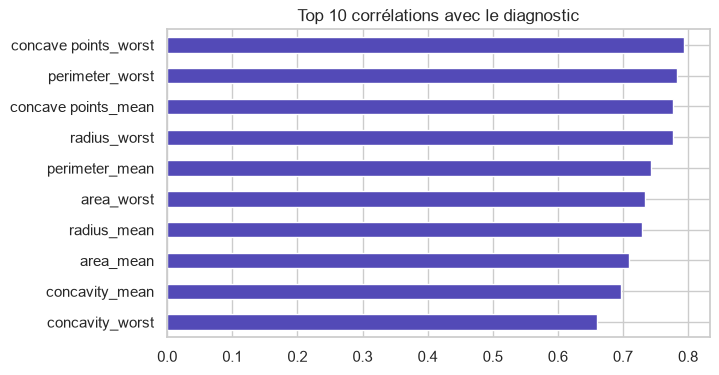

In [16]:
cor_cible.head(10)[::-1].plot.barh(color="#534AB7", figsize=(7, 4))
plt.title("Top 10 corrélations avec le diagnostic")
plt.show()

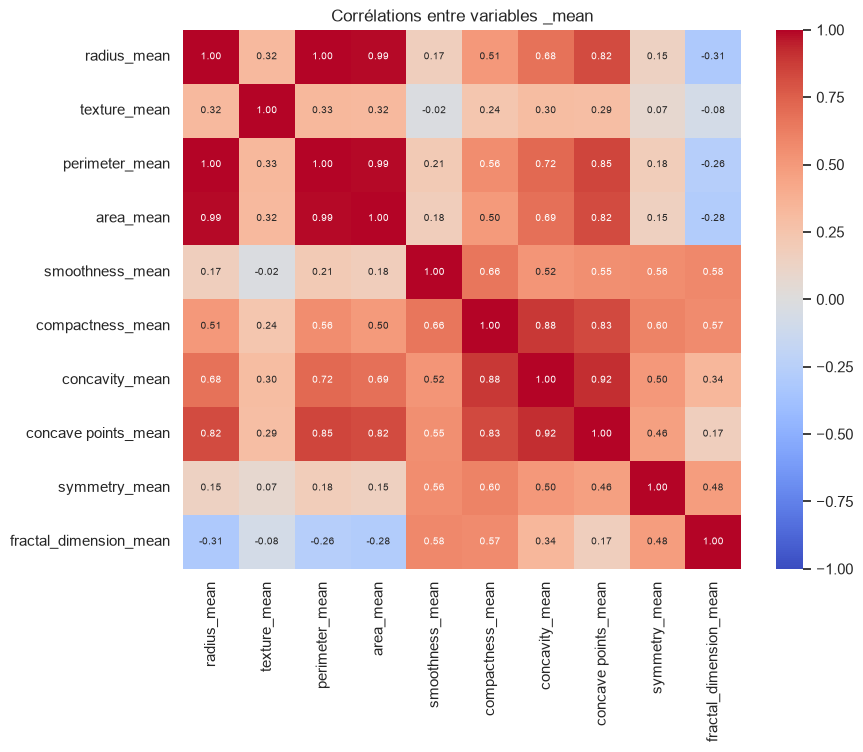

In [17]:
plt.figure(figsize=(9, 7))
sns.heatmap(num[mean_cols].corr(), cmap="coolwarm", vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Corrélations entre variables _mean")
plt.show()

In [18]:
# Multicolinéarité : paires fortement corrélées
cm = num.corr().abs()
paires = cm.where(np.triu(np.ones(cm.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print("Paires avec |r| > 0,9 :", (paires > 0.9).sum())
paires.head(8).round(3)

Paires avec |r| > 0,9 : 21


radius_mean      perimeter_mean     0.998
radius_worst     perimeter_worst    0.994
radius_mean      area_mean          0.987
perimeter_mean   area_mean          0.987
radius_worst     area_worst         0.984
perimeter_worst  area_worst         0.978
radius_se        perimeter_se       0.973
perimeter_mean   perimeter_worst    0.970
dtype: float64

`radius`, `perimeter` et `area` sont quasi redondantes (r jusqu'à 0,998), ce qui est normal car la géométrie les relie. Pour un premier modèle simple, on peut n'en garder qu'une.

## 6. Nettoyage

1. Suppression de `Unnamed: 32` (colonne vide)
2. Encodage de `diagnosis` : B = 0, M = 1
3. Renommage de `concave points_*` en `concave_points_*` (pas d'espaces dans les noms)

On ne touche ni aux outliers ni aux zéros (voir plus haut). La normalisation se fera plus tard, après la séparation train/test, pour éviter la fuite de données.

In [19]:
df_clean = df.drop(columns=["Unnamed: 32"]).copy()
df_clean.columns = [c.replace(" ", "_") for c in df_clean.columns]
df_clean["diagnosis"] = df_clean["diagnosis"].map({"B": 0, "M": 1})

print("Dimensions :", df_clean.shape)
print("Valeurs manquantes :", df_clean.isna().sum().sum())
print(df_clean["diagnosis"].value_counts())
df_clean.head()

Dimensions : (569, 32)
Valeurs manquantes : 0
diagnosis
0    357
1    212
Name: count, dtype: int64


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 7. Export

In [20]:
df_clean.to_csv("bcw_data_clean.csv", index=False)
print("Fichier enregistré : bcw_data_clean.csv")

Fichier enregistré : bcw_data_clean.csv


## Pour la suite (perceptron)

- Retirer `id` des variables explicatives
- Séparer train/test, puis standardiser (moyenne et écart-type calculés sur le train uniquement)
- Pour un premier modèle simple : `concave_points_worst`, `texture_worst`, `smoothness_worst`